In [39]:
import pandas as pd
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent))

from analysis_functions import get_power_data, compute_baseline_stats, detect_power_surges, compute_surge_vs_simpipe_start_endtime_diffs
from analysis_functions import plot_enhanced_visualization

In [68]:
# Data to compare
runNr = "4"
simpipe_datetime_shift = 60 # minutes to shift data
#simpipe_day_shift = 60 # minutes; run*.dat has only clock times, which parse as today

base_path = "../../../data/alignment-step-only"
data_path = f"{base_path}/Power.xls"             # Tapo Smart plug data measurement
corresponding_dataset_path = f"{base_path}/run{runNr}.dat"  # Carbontracker/SIMPIPE data

In [69]:
power_data = get_power_data(data_path)                                                                                  # Tapo Smart plug data
carbontracker_simpipe_data = pd.read_csv(corresponding_dataset_path, sep=r'\s+', comment='#', header=0)      # Carbontracker/SIMPIPE data

total_shift = simpipe_datetime_shift
if total_shift != 0:
    carbontracker_simpipe_data = carbontracker_simpipe_data.copy()
    # Convert start and stop columns to datetime if they aren't already
    carbontracker_simpipe_data["start"] = pd.to_datetime(carbontracker_simpipe_data["start"])
    carbontracker_simpipe_data["stop"] = pd.to_datetime(carbontracker_simpipe_data["stop"])
    # Now apply the time shift
    carbontracker_simpipe_data["start"] += pd.Timedelta(minutes=total_shift)
    carbontracker_simpipe_data["stop"] += pd.Timedelta(minutes=total_shift)

In [70]:
# runNr 1
min_duration_minutes = 60           # minimum duration (s) for a surge to be considered
surge_threshold_multiplier = 1.05   # threshold multiplier for surge detection (relative to baseline)

# runNr 2
#min_duration_minutes = 60           # minimum duration (s) for a surge to be considered
#surge_threshold_multiplier = 1.07   # threshold multiplier for surge detection (relative to baseline)

# runNr 3
#min_duration_minutes = 60           # minimum duration (s) for a surge to be considered
#surge_threshold_multiplier = 1.01   # threshold multiplier for surge detection (relative to baseline)

baseline_stats = compute_baseline_stats(df=power_data, percentile_threshold=70, print_stats=True)
surge_periods, surge_threshold = detect_power_surges(power_data, baseline_stats, min_duration_minutes=min_duration_minutes, surge_threshold_multiplier=surge_threshold_multiplier)

     compute_baseline_stats -- Baseline analysis...
      Power threshold for baseline: 225.9 W
      Baseline periods: 201 out of 288 (69.8%)
      Mean baseline power: 209.0 W
      Median baseline power: 209.0 W
      Std baseline power: 4.6 W
      Power range: 198.0 - 225.0 W
      Mean baseline energy per period: 0.017415 kWh
      Total baseline energy: 3.5005 kWh



Carbontracker period: 2026-10-29 11:33:56 to 2026-10-29 13:08:34
Power data period: 2026-10-29 10:10:00 to 2026-10-30 10:05:00


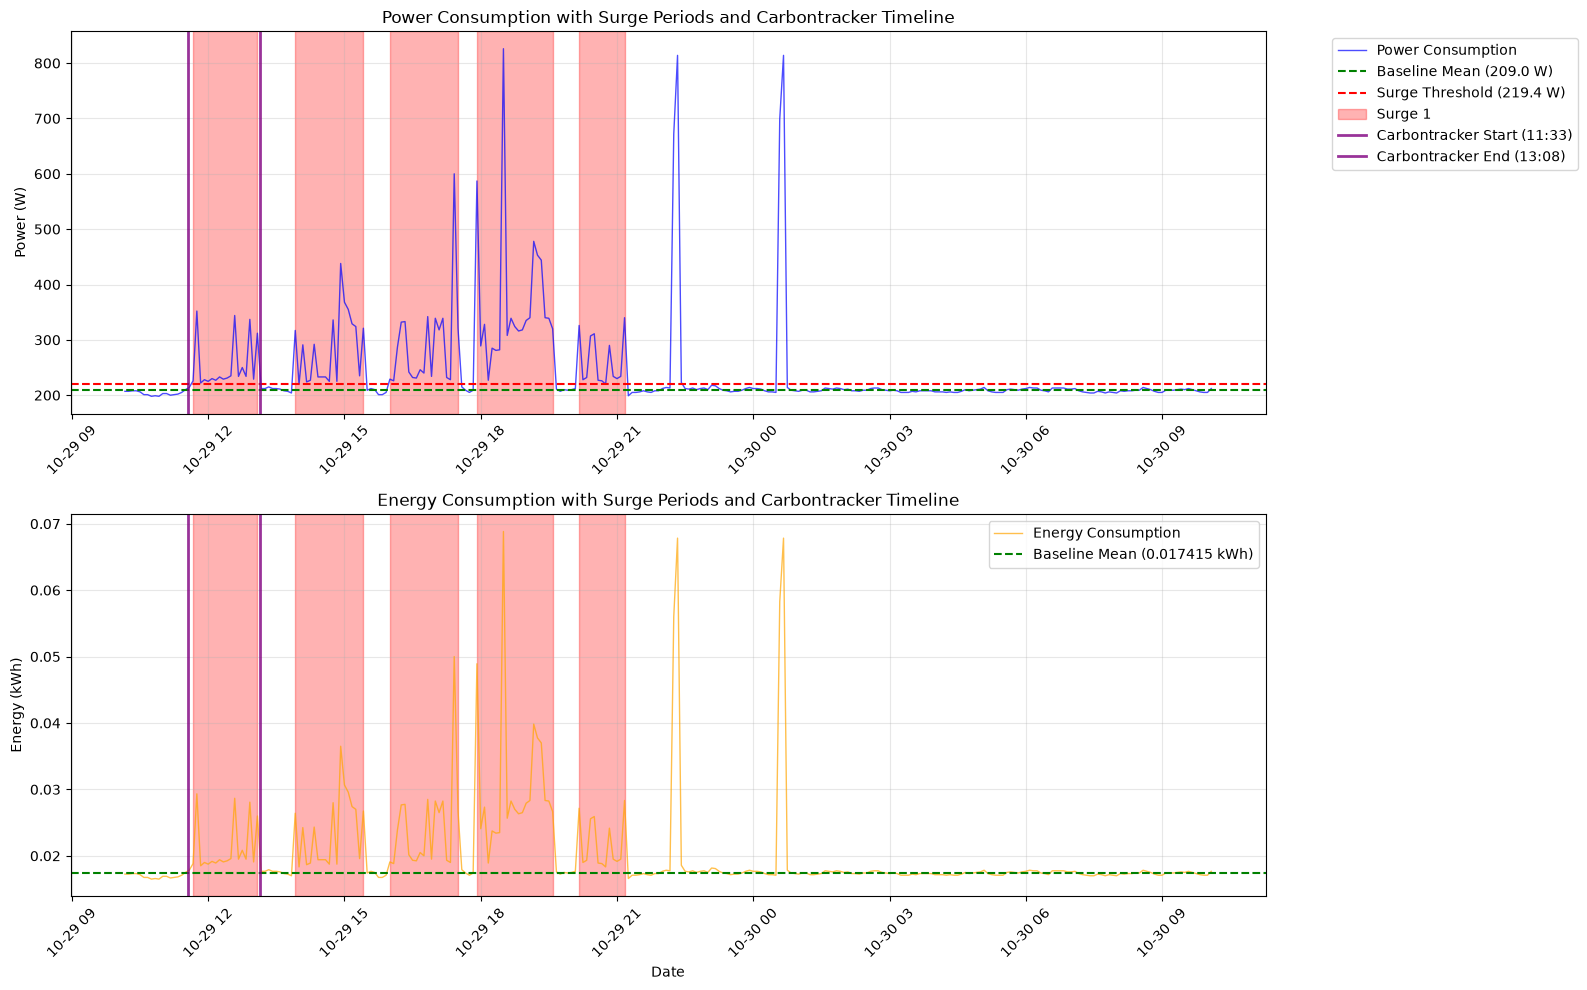

=== CARBONTRACKER vs POWER SURGE ANALYSIS ===
Carbontracker monitoring period: 11:33 - 13:08
Carbontracker duration: 1.58 hours

Overlap analysis with detected surge periods:
  Surge 1: 100.0% overlap (85.0/85.0 minutes)
    Surge: 11:40 - 13:05
    Overlap: 11:40 - 13:05
  Surge 2: No overlap
    Surge: 13:55 - 15:25
  Surge 3: No overlap
    Surge: 16:00 - 17:30
  Surge 4: No overlap
    Surge: 17:55 - 19:35
  Surge 5: No overlap
    Surge: 20:10 - 21:10

Power statistics during Carbontracker period:
  Average power: 252.2 W
  Peak power: 352.0 W
  Total energy: 0.3993 kWh
  Carbontracker reported energy: 9.1640 kWh
  Energy difference: 8.7647 kWh


In [71]:
plot_enhanced_visualization(carbontracker_simpipe_data, power_data, baseline_stats, surge_periods, surge_threshold)

In [44]:
compute_surge_vs_simpipe_start_endtime_diffs(carbontracker_simpipe_data=carbontracker_simpipe_data, surge_periods=surge_periods)

=== TIME DIFFERENCE ANALYSIS ===
Carbontracker start time: 2026-10-28 18:01:12
Carbontracker stop time: 2026-10-28 19:36:38
Carbontracker duration: 95.4 minutes

Surge 1:
  Surge start: 2026-10-29 11:40:00
  Surge end: 2026-10-29 13:05:00
  Start time difference from carbontracker start:
    +17.65 hours (1058.8 minutes) AFTER carbontracker start
  End time difference from carbontracker stop:
    +17.47 hours (1048.4 minutes) AFTER carbontracker stop

Surge 2:
  Surge start: 2026-10-29 13:55:00
  Surge end: 2026-10-29 15:25:00
  Start time difference from carbontracker start:
    +19.90 hours (1193.8 minutes) AFTER carbontracker start
  End time difference from carbontracker stop:
    +19.81 hours (1188.4 minutes) AFTER carbontracker stop

Surge 3:
  Surge start: 2026-10-29 16:00:00
  Surge end: 2026-10-29 17:30:00
  Start time difference from carbontracker start:
    +21.98 hours (1318.8 minutes) AFTER carbontracker start
  End time difference from carbontracker stop:
    +21.89 hours

# Analysis of time diffs

...

We therefore compute the differences
* Dstart = diff(simpipe_start - estimated_power_surge_start)
* Dend = diff(simpipe_end - estimated_power_surge_end)
* Delta = (simpipe_start - simpipe_end) - Dend
* Kappa = (simpipe_start - simpipe_end) - Delta

In [45]:
# Data for surge time differences.
# data contains table of surge time differences between Tapo Smart plug and Carbontracker/SIMPIPE for all runs.
# Columns: Configuration, RunNr, Start_Time_Diff_minutes, End_Time_Diff_meconds, SIMPIPE_Duration_minutes
surge_time_diffs = pd.read_csv("../../../data/alignment-step-only/surge_time_diffs.dat", sep=r'\s+', comment='#', header=0)
# isna
nan_values = surge_time_diffs[surge_time_diffs.isna()["duration"]]
# remove NaN values
surge_time_diffs = surge_time_diffs.dropna()
# compute delta = End_Time_Diff_meconds - Start_Time_Diff_minutes
surge_time_diffs['Delta'] = surge_time_diffs['duration'] - surge_time_diffs['endDiff']
# compute tapo_power_duration
surge_time_diffs['tapo_power_duration'] = surge_time_diffs['startDiff'] - surge_time_diffs['endDiff'] + surge_time_diffs['duration']
# duration diff (diff between estimated power surge in Tapo data and SIMPIPE data)
surge_time_diffs['tapo_simpipe_duration_diff'] = surge_time_diffs['duration'] - surge_time_diffs['tapo_power_duration']

In [46]:
surge_time_diffs

,configuration,runNr,startDiff,endDiff,duration,Delta,tapo_power_duration,tapo_simpipe_duration_diff
0,power-surge,1,0.10,-0.06,94.6,94.66,94.76,-0.16
1,power-surge,2,0.06,-0.04,95.7,95.74,95.80,-0.10
2,power-surge,3,0.05,-0.02,93.8,93.82,93.87,-0.07
3,power-surge,4,-0.10,-0.03,95.4,95.43,95.33,0.07


In [47]:
surge_time_diffs.startDiff.mean()
#surge_time_diffs.endDiff.mean()

np.float64(0.027500000000000004)

In [48]:
# these configurations needs to be rerun:
nan_values

,configuration,runNr,startDiff,endDiff,duration


In [49]:
baseline_stats

{'threshold_power': np.float64(225.89999999999998),
 'baseline_periods': 201,
 'total_periods': 288,
 'baseline_percentage': 69.79166666666666,
 'mean_power': np.float64(208.98507462686567),
 'median_power': np.float64(209.0),
 'std_power': np.float64(4.553545444969555),
 'min_power': np.int64(198),
 'max_power': np.int64(225),
 'mean_energy': np.float64(0.017415422885572136),
 'total_baseline_energy': np.float64(3.5004999999999997)}

In [50]:
power_data

,Date,Power(W),Energy(kWh)
1,2026-10-29 10:10:00,207,0.017250
2,2026-10-29 10:15:00,207,0.017250
3,2026-10-29 10:20:00,208,0.017333
4,2026-10-29 10:25:00,208,0.017333
5,2026-10-29 10:30:00,206,0.017167
...,...,...,...
284,2026-10-30 09:45:00,208,0.017333
285,2026-10-30 09:50:00,206,0.017167
286,2026-10-30 09:55:00,205,0.017083
287,2026-10-30 10:00:00,205,0.017083
